# 01 — Primera prueba: análisis-síntesis LPC10 sobre PTDB-TUG

**TPI Señales y Sistemas 2026 — Grupo 3: Codificación de la voz**

Objetivo de esta prueba (pedido del tutor): correr el análisis-síntesis LPC10 del capítulo con **algunas señales reales** de
PTDB-TUG y comparar la F0 que estima el capítulo con la F0 de referencia del laringógrafo.

Todo el procesamiento sigue el capítulo *Dutoit, Moreau & Kroon (2009), "How is speech processed in a cell phone
conversation?"*. Cada celda indica la sección que traduce. Lo único agregado es lo que exige la base de datos
(remuestreo de 48 a 8 kHz y lectura de la referencia) y las métricas de comparación.

| Paso | Qué hace | Capítulo |
|---|---|---|
| 1 | Cargar señales y F0 de referencia | — (base de datos) |
| 2 | Remuestrear 48 → 8 kHz con filtro antialiasing | — (sugerencia del tutor) |
| 3 | Espectrograma de banda ancha | 1.2.1 |
| 4 | Análisis LPC de una trama sonora: envolvente, polos, residuo | 1.2.2 |
| 5 | Estimación de pitch y sonoro/sordo con el residuo | 1.2.6 |
| 6 | Síntesis LPC10 del archivo completo | 1.2.4 – 1.2.6 |
| 7 | F0 estimada vs F0 del laringógrafo | — (métricas) |

## 0. Configuración

Solo usa NumPy, SciPy y Matplotlib (vienen instalados en Colab).

`DATA_DIR` es la carpeta que contiene `SPEECH DATA/` de PTDB-TUG. Si los archivos no están, la celda de descarga baja
solo los que se usan en esta prueba (≈ 6 MB) directamente del servidor de la base.

In [1]:
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly, lfilter, freqz, tf2zpk, butter, spectrogram, periodogram
from scipy.linalg import solve_toeplitz
from IPython.display import Audio, display

# Carpeta con "SPEECH DATA/" (en Colab cambiar por la ruta en Drive, p. ej. "/content/drive/MyDrive/ptdb-tug")
DATA_DIR = Path("../data/ptdb-tug")
FIG_DIR = Path("../results/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_DIR = Path("../results/audio"); AUDIO_DIR.mkdir(parents=True, exist_ok=True)

HABLANTES = ["F01", "F02", "M01", "M02"]   # 2 mujeres y 2 hombres
FRASES = ["sa1", "sa2"]                     # las frases sa las leen los 20 hablantes

plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["axes.grid"] = True
np.random.seed(0)  # la excitación sorda es ruido aleatorio: fijamos la semilla para que sea reproducible

In [2]:
URL_BASE = "https://www2.spsc.tugraz.at/databases/PTDB-TUG/SPEECH%20DATA"

def ruta(tipo, hablante, frase):
    # tipo: "MIC" (micrófono, .wav) o "REF" (F0 de referencia, .f0)
    sexo = "FEMALE" if hablante.startswith("F") else "MALE"
    ext = "wav" if tipo == "MIC" else "f0"
    nombre = f"{tipo.lower()}_{hablante}_{frase}.{ext}"
    return DATA_DIR / "SPEECH DATA" / sexo / tipo / hablante / nombre, f"{URL_BASE}/{sexo}/{tipo}/{hablante}/{nombre}"

for h in HABLANTES:
    for f in FRASES:
        for tipo in ["MIC", "REF"]:
            local, url = ruta(tipo, h, f)
            if not local.exists():
                local.parent.mkdir(parents=True, exist_ok=True)
                print("descargando", local.name)
                urllib.request.urlretrieve(url, local)
print("datos listos en", DATA_DIR.resolve())

datos listos en C:\Users\VICTUS\Documents\2026\SyS\TPI\tpi-voz\data\ptdb-tug


## 1. Carga de señales y referencia

- Micrófono: WAV mono, 48 kHz, 16 bits. Se normaliza a [-1, 1).
- Referencia (`.f0`): salida de RAPT sobre el laringógrafo, una fila cada **10 ms** (ventana de 32 ms). Columnas:
  F0 [Hz], probabilidad de sonoridad, RMS, pico de correlación. Las tramas sordas tienen F0 = 0.

In [3]:
def cargar(hablante, frase):
    fs, x = wavfile.read(ruta("MIC", hablante, frase)[0])
    x = x.astype(float) / 32768.0
    ref = np.loadtxt(ruta("REF", hablante, frase)[0])
    return fs, x, ref[:, 0]          # nos quedamos con la columna de F0

fs48, x48, f0_ref = cargar("F01", "sa1")
print(f"fs = {fs48} Hz, duración = {len(x48)/fs48:.2f} s, tramas de referencia = {len(f0_ref)} (cada 10 ms)")
print(f"F0 media de referencia (tramas sonoras): {f0_ref[f0_ref > 0].mean():.0f} Hz")

fs = 48000 Hz, duración = 7.99 s, tramas de referencia = 793 (cada 10 ms)
F0 media de referencia (tramas sonoras): 195 Hz


## 2. Remuestreo de 48 kHz a 8 kHz

El capítulo trabaja con voz telefónica a 8 kHz (orden LPC p = 10). Bajar de 48 a 8 kHz es diezmar por M = 6.
Antes hay que filtrar pasabajos con corte en π/6 (4 kHz) para que lo que está entre 4 y 24 kHz no se pliegue sobre
la banda útil (aliasing). `resample_poly(x, 1, 6)` hace las dos cosas: filtro FIR antialiasing + diezmado.

Además se aplica un pasa-altos suave (Butterworth de orden 4, 70 Hz). El capítulo trabaja sobre `speech_HF`, una versión
filtrada pasa-altos de la señal; en PTDB-TUG hace falta porque los 2 s de silencio inicial tienen ruido de baja
frecuencia (el ventilador de la notebook de grabación, según el reporte de la base) que, si no, el estimador de pitch
confunde con voz.

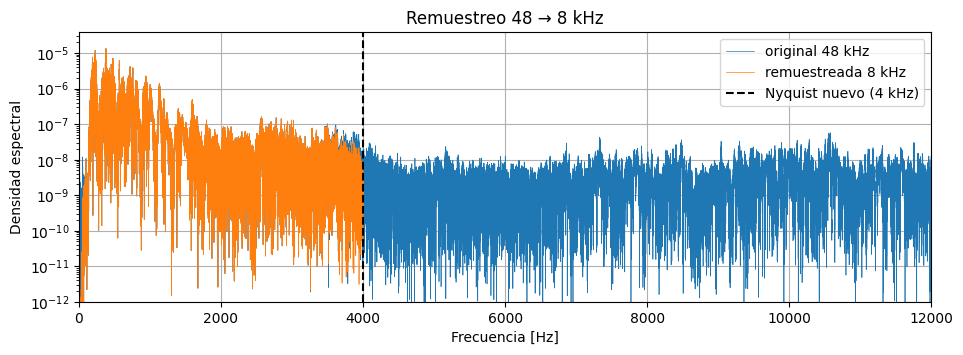

In [4]:
FS = 8000
M = fs48 // FS                       # factor de diezmado = 6
B_HP, A_HP = butter(4, 70, btype="highpass", fs=FS)

def preprocesar(x48):
    x8 = resample_poly(x48, 1, M)    # antialiasing + diezmado
    return lfilter(B_HP, A_HP, x8)   # equivalente a speech_HF del capítulo

speech = preprocesar(x48)

# Espectro antes y después: el remuestreo conserva la banda 0-4 kHz y elimina el resto
f1, P1 = periodogram(x48, fs48)
f2, P2 = periodogram(speech, FS)
plt.semilogy(f1, P1 + 1e-14, lw=0.5, label="original 48 kHz")
plt.semilogy(f2, P2 + 1e-14, lw=0.5, label="remuestreada 8 kHz")
plt.axvline(FS / 2, color="k", ls="--", label="Nyquist nuevo (4 kHz)")
plt.xlim(0, 12000); plt.ylim(1e-12, None)
plt.xlabel("Frecuencia [Hz]"); plt.ylabel("Densidad espectral"); plt.legend(); plt.title("Remuestreo 48 → 8 kHz")
plt.savefig(FIG_DIR / "01_remuestreo.png", dpi=120, bbox_inches="tight"); plt.show()

display(Audio(speech, rate=FS))

## 3. Espectrograma de banda ancha (capítulo 1.2.1)

Ventana de Hamming de 40 muestras (5 ms, menor que un período de pitch) y DFT de 512 puntos, como en el capítulo:
los períodos de pitch aparecen como líneas verticales y los formantes como bandas horizontales oscuras.

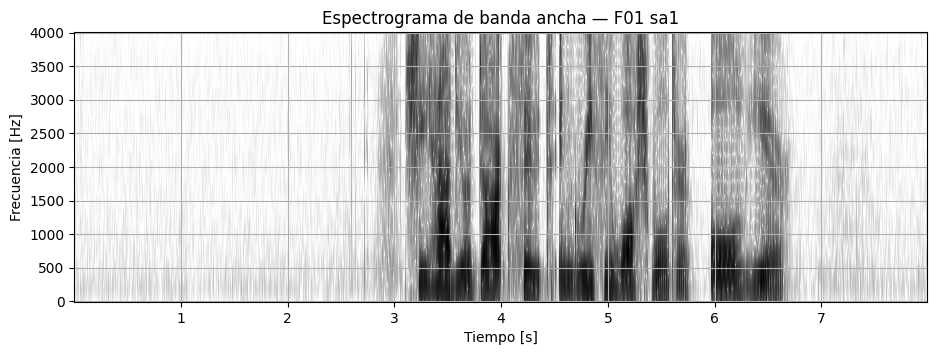

In [5]:
f, t, S = spectrogram(speech, FS, window=np.hamming(40), nperseg=40, noverlap=30, nfft=512)
plt.pcolormesh(t, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="gray_r")
plt.xlabel("Tiempo [s]"); plt.ylabel("Frecuencia [Hz]"); plt.title("Espectrograma de banda ancha — F01 sa1")
plt.savefig(FIG_DIR / "01_espectrograma.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Análisis LPC de una trama sonora (capítulo 1.2.2)

### 4.1 Función `lpc`

Equivalente a `lpc(x, p)` de MATLAB que usa el capítulo: método de autocorrelación y algoritmo de **Levinson-Durbin**
para resolver las ecuaciones de Yule-Walker (ec. 1.5). Devuelve los coeficientes de

$$A_p(z) = 1 + \sum_{i=1}^{p} a_i z^{-i}$$

y la varianza del error de predicción $\sigma^2$ (ec. 1.6).

In [6]:
def lpc(x, p):
    N = len(x)
    # autocorrelación (sesgada, dividida por N como en MATLAB) para k = 0..p
    r = np.array([np.dot(x[:N - k], x[k:]) for k in range(p + 1)]) / N
    a = np.zeros(p + 1); a[0] = 1.0
    err = r[0]
    if err <= 0:                     # trama de silencio digital
        return a, 0.0
    for i in range(1, p + 1):        # Levinson-Durbin
        k = -(r[i] + np.dot(a[1:i], r[i - 1:0:-1])) / err   # coeficiente de reflexión k_i
        a_prev = a.copy()
        for j in range(1, i):
            a[j] = a_prev[j] + k * a_prev[i - j]
        a[i] = k
        err *= (1 - k ** 2)
    return a, err

# Verificación: Levinson-Durbin debe dar lo mismo que resolver Yule-Walker con un solver de matrices Toeplitz
trama_prueba = speech[24000:24240] * np.hamming(240)
a_lev, _ = lpc(trama_prueba, 10)
r = np.array([np.dot(trama_prueba[:240 - k], trama_prueba[k:]) for k in range(11)]) / 240
a_toe = solve_toeplitz(r[:10], -r[1:11])
print("diferencia máxima Levinson vs Toeplitz:", np.max(np.abs(a_lev[1:] - a_toe)))

diferencia máxima Levinson vs Toeplitz: 5.551115123125783e-17


### 4.2 Elegir una trama sonora

Trama de 30 ms (240 muestras a 8 kHz). Se toma una trama donde el laringógrafo indica voz (F0 de referencia > 0) y que
tenga mucha energía (una vocal).

trama 348 (t = 3.48 s), F0 de referencia = 237 Hz


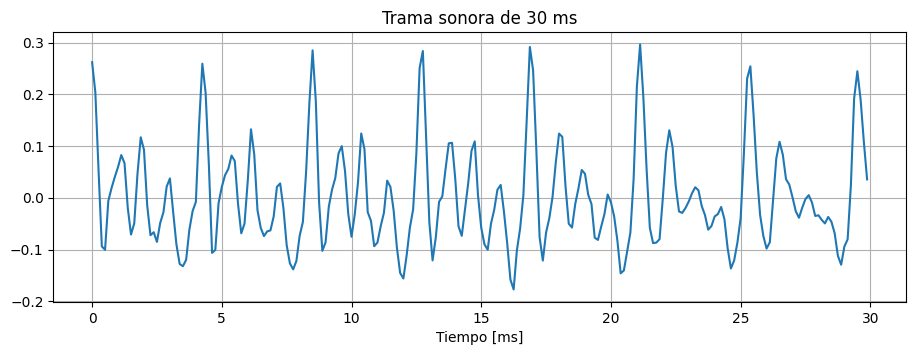

In [7]:
L_TRAMA, SALTO, P = 240, 80, 10      # 30 ms, 10 ms, orden 10 (capítulo 1.1.3)

n_tramas = (len(speech) - L_TRAMA) // SALTO + 1
energia = np.array([np.sum(speech[i * SALTO:i * SALTO + L_TRAMA] ** 2) for i in range(n_tramas)])
sonoras = np.where(f0_ref[:n_tramas] > 0)[0]
i_trama = sonoras[np.argmax(energia[sonoras])]
input_frame = speech[i_trama * SALTO:i_trama * SALTO + L_TRAMA]
print(f"trama {i_trama} (t = {i_trama * SALTO / FS:.2f} s), F0 de referencia = {f0_ref[i_trama]:.0f} Hz")

t_ms = np.arange(L_TRAMA) / FS * 1000
plt.plot(t_ms, input_frame); plt.xlabel("Tiempo [ms]"); plt.title("Trama sonora de 30 ms"); plt.show()

### 4.3 Filtro inverso A(z), filtro de síntesis 1/A(z) y envolvente espectral

Como en el capítulo: la respuesta en frecuencia de $1/A(z)$ (escalada por $\sigma$) se apoya sobre el periodograma de la
trama y sigue su **envolvente**; los picos de la envolvente son los **formantes**. $A(z)$ tiene antirresonancias donde
la trama tiene formantes, por eso se lo llama filtro inverso.

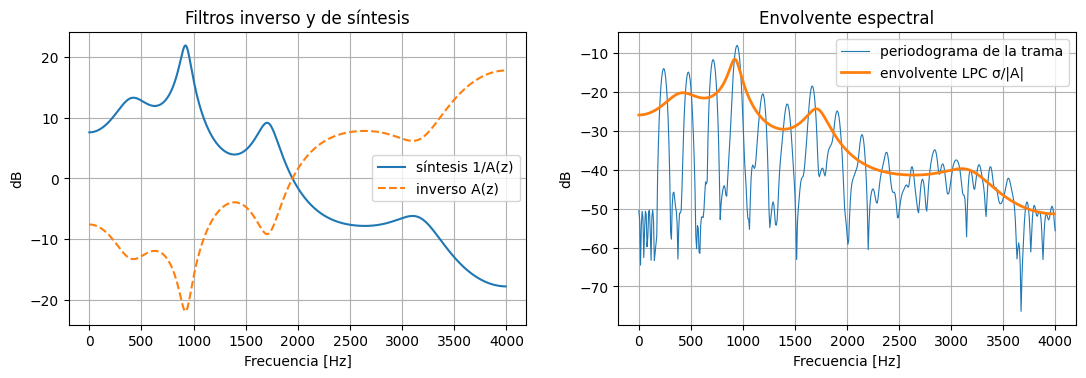

In [8]:
ai, sigma2 = lpc(input_frame * np.hamming(L_TRAMA), P)
sigma = np.sqrt(sigma2)

w, HI = freqz(ai, 1, worN=512, fs=FS)       # filtro inverso A(z)
w, H = freqz(1, ai, worN=512, fs=FS)        # filtro de síntesis 1/A(z)

# Periodograma bilateral (|X|^2 / N) para que esté en la misma escala que sigma^2 |H|^2
X = np.fft.rfft(input_frame * np.hamming(L_TRAMA), 1024)
f_X = np.fft.rfftfreq(1024, 1 / FS)
Pxx = np.abs(X) ** 2 / L_TRAMA

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(w, 20 * np.log10(np.abs(H)), label="síntesis 1/A(z)")
ax[0].plot(w, 20 * np.log10(np.abs(HI)), "--", label="inverso A(z)")
ax[0].set_xlabel("Frecuencia [Hz]"); ax[0].set_ylabel("dB"); ax[0].legend(); ax[0].set_title("Filtros inverso y de síntesis")
ax[1].plot(f_X, 10 * np.log10(Pxx + 1e-12), lw=0.8, label="periodograma de la trama")
ax[1].plot(w, 20 * np.log10(sigma * np.abs(H)), lw=2, label="envolvente LPC σ/|A|")
ax[1].set_xlabel("Frecuencia [Hz]"); ax[1].set_ylabel("dB"); ax[1].legend(); ax[1].set_title("Envolvente espectral")
plt.savefig(FIG_DIR / "01_envolvente_lpc.png", dpi=120, bbox_inches="tight"); plt.show()

### 4.4 Polos de 1/A(z) en el plano Z

El ajuste LPC ubica los polos **cerca del círculo unitario** en los ángulos de los formantes: ángulo $\theta$ ↔
frecuencia $f = \theta \, f_s / 2\pi$. Todos dentro del círculo ⇒ filtro de síntesis estable.

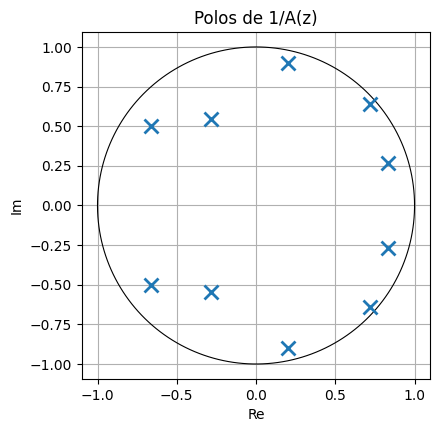

Polo  |radio|  frecuencia [Hz]
      0.876       399
      0.961       925
      0.923      1716
      0.618      2613
      0.830      3171
¿Estable? (todos los |polos| < 1): True


In [9]:
z, p_polos, k = tf2zpk([1], ai)
th = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(4.5, 4.5))
plt.plot(np.cos(th), np.sin(th), "k", lw=0.8)
plt.plot(p_polos.real, p_polos.imag, "x", ms=10, mew=2)
plt.axis("equal"); plt.xlabel("Re"); plt.ylabel("Im"); plt.title("Polos de 1/A(z)")
plt.savefig(FIG_DIR / "01_polos.png", dpi=120, bbox_inches="tight"); plt.show()

polos_sup = p_polos[p_polos.imag > 0]
orden = np.argsort(np.angle(polos_sup))
print("Polo  |radio|  frecuencia [Hz]")
for pz in polos_sup[orden]:
    print(f"      {abs(pz):.3f}   {np.angle(pz) * FS / (2 * np.pi):7.0f}")
print("¿Estable? (todos los |polos| < 1):", np.all(np.abs(p_polos) < 1))

### 4.5 Residuo de predicción (filtrado inverso, ec. 1.3)

$e(n) = \sum_{i=0}^{p} a_i\, s(n-i)$: pasar la trama por $A(z)$. El residuo tiene espectro **casi plano** (el filtrado
inverso decorrelaciona la voz) pero conserva el pitch: se ven pulsos cada $T_0$ y armónicos en el espectro.
Pasar el residuo por $1/A(z)$ devuelve la trama original.

error de reconstrucción residuo → 1/A(z): 1.942890293094024e-16


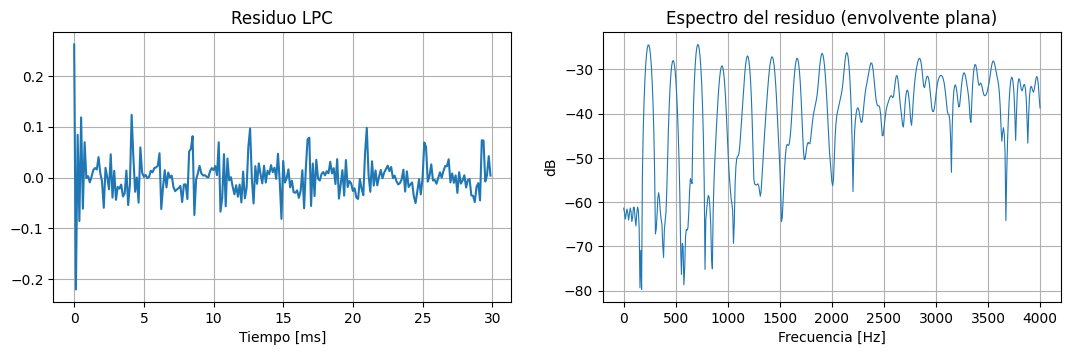

In [10]:
LP_residual = lfilter(ai, 1, input_frame)
reconstruida = lfilter([1], ai, LP_residual)
print("error de reconstrucción residuo → 1/A(z):", np.max(np.abs(reconstruida - input_frame)))

E = np.fft.rfft(LP_residual * np.hamming(L_TRAMA), 1024)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(t_ms, LP_residual); ax[0].set_xlabel("Tiempo [ms]"); ax[0].set_title("Residuo LPC")
ax[1].plot(f_X, 10 * np.log10(np.abs(E) ** 2 / L_TRAMA + 1e-12), lw=0.8)
ax[1].set_xlabel("Frecuencia [Hz]"); ax[1].set_ylabel("dB"); ax[1].set_title("Espectro del residuo (envolvente plana)")
plt.savefig(FIG_DIR / "01_residuo.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. Estimación de pitch y decisión sonoro/sordo (capítulo 1.2.6)

El capítulo describe su función `pitch()` así: *T0 es el máximo de la autocorrelación del residuo LPC; la decisión
sonoro/sordo se basa en el cociente entre ese máximo y la varianza del residuo; si la trama es sorda, T0 = 0.*

Parámetros que el capítulo **no** especifica y que fijamos nosotros:

- Rango de búsqueda de F0: 60 – 400 Hz (retardos de 20 a 133 muestras a 8 kHz).
- Umbral sonoro/sordo: **0,25**. Se eligió probando 0,10 a 0,30 sobre las 8 señales de esta prueba; es el que da menor
  error de decisión sonoro/sordo contra el laringógrafo. Hay que revisarlo con más datos.

In [11]:
F0_MIN, F0_MAX = 60, 400
UMBRAL_VUV = 0.25

def pitch(frame, fs=FS, p=P):
    # T0 en muestras (0 si la trama es sorda), como la función pitch() del capítulo
    a, _ = lpc(frame * np.hamming(len(frame)), p)
    residuo = lfilter(a, 1, frame * np.hamming(len(frame)))
    r = np.correlate(residuo, residuo, mode="full")[len(residuo) - 1:]   # r[k], k >= 0
    if r[0] <= 0:
        return 0
    k_min, k_max = int(fs / F0_MAX), int(fs / F0_MIN)
    T0 = k_min + np.argmax(r[k_min:k_max + 1])
    return T0 if r[T0] / r[0] > UMBRAL_VUV else 0

T0 = pitch(input_frame)
print(f"T0 = {T0} muestras → F0 = {FS / T0:.0f} Hz (referencia: {f0_ref[i_trama]:.0f} Hz)")

T0 = 34 muestras → F0 = 235 Hz (referencia: 237 Hz)


## 6. Síntesis LPC10 del archivo completo (capítulo 1.2.4 – 1.2.6)

Traducción directa del código del capítulo:

- Tramas de análisis de 30 ms con salto de 10 ms y ventana de Hamming; LPC de orden 10.
- Por cada trama se sintetizan 10 ms (80 muestras).
- Trama **sonora**: tren de pulsos de período N0 con ganancia `sigma / sqrt(1/N0)`, manejando el *offset* para que los
  períodos sigan entre tramas (1.2.4).
- Trama **sorda**: ruido blanco gaussiano con ganancia `sigma` (1.2.5).
- El filtro de síntesis **conserva su estado interno** entre tramas (`zi`), igual que `[synt_frame, z] = filter(...)`.

La función recibe opcionalmente un vector `f0_externa` (una F0 por trama, 0 = sorda). Así, más adelante, se puede meter en
el decodificador la F0 de otro estimador (cepstrum, YIN) o la del laringógrafo, como pidió el tutor.

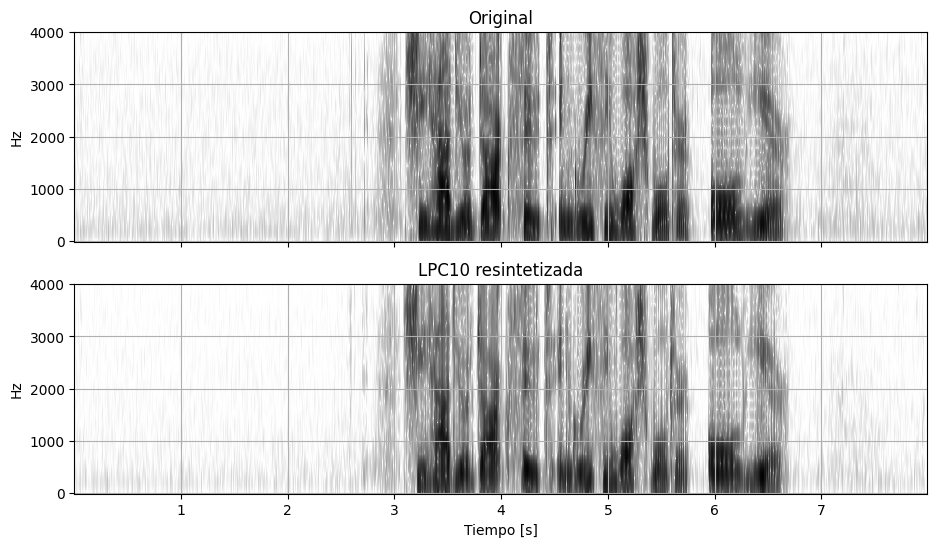

Original:


LPC10 (F0 del capítulo):


In [12]:
def lpc10(speech_HF, f0_externa=None, fs=FS):
    n_tramas = (len(speech_HF) - L_TRAMA) // SALTO + 1
    z = np.zeros(P)                  # estado interno del filtro de síntesis
    offset = 0
    synt_speech = []
    f0_usada = np.zeros(n_tramas)
    for i in range(n_tramas):
        input_frame = speech_HF[i * SALTO:i * SALTO + L_TRAMA]
        ai, sigma2 = lpc(input_frame * np.hamming(L_TRAMA), P)
        sigma = np.sqrt(sigma2)

        if f0_externa is None:
            N0 = pitch(input_frame)                       # estimador del capítulo
        else:
            N0 = int(round(fs / f0_externa[i])) if f0_externa[i] > 0 else 0
        f0_usada[i] = fs / N0 if N0 > 0 else 0

        if N0 != 0:                                       # trama sonora
            if offset >= SALTO:
                excitation = np.zeros(SALTO)
                offset -= SALTO
            else:
                excitation = list(np.zeros(offset))      # completar el período que quedó pendiente
                for _ in range((SALTO - offset) // N0):
                    excitation += [1.0] + [0.0] * (N0 - 1)
                flush = SALTO - len(excitation)
                if flush != 0:                            # período parcial al final de la trama
                    excitation += [1.0] + [0.0] * (flush - 1)
                    offset = N0 - flush
                else:
                    offset = 0
                excitation = np.array(excitation)
            gain = sigma / np.sqrt(1 / N0)
        else:                                             # trama sorda
            excitation = np.random.randn(SALTO)
            gain = sigma
            offset = 0

        synt_frame, z = lfilter([gain], ai, excitation, zi=z)
        synt_speech.append(synt_frame)
    return np.concatenate(synt_speech), f0_usada

synt_speech, f0_cap = lpc10(speech)

f, t, S1 = spectrogram(speech, FS, window=np.hamming(40), nperseg=40, noverlap=30, nfft=512)
f, t2, S2 = spectrogram(synt_speech, FS, window=np.hamming(40), nperseg=40, noverlap=30, nfft=512)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].pcolormesh(t, f, 10 * np.log10(S1 + 1e-12), shading="auto", cmap="gray_r"); ax[0].set_title("Original")
ax[1].pcolormesh(t2, f, 10 * np.log10(S2 + 1e-12), shading="auto", cmap="gray_r"); ax[1].set_title("LPC10 resintetizada")
ax[1].set_xlabel("Tiempo [s]")
for a_ in ax: a_.set_ylabel("Hz")
plt.savefig(FIG_DIR / "01_lpc10_espectrogramas.png", dpi=120, bbox_inches="tight"); plt.show()

print("Original:"); display(Audio(speech, rate=FS))
print("LPC10 (F0 del capítulo):"); display(Audio(synt_speech, rate=FS))

### 6.1 Caso de referencia: decodificar con la F0 del laringógrafo

La misma síntesis, pero usando la F0 de referencia (pitch "perfecto"). Es la mejor calidad posible del LPC10 con esta
excitación; sirve para separar el efecto de los errores de pitch del resto de las limitaciones del modelo.

In [13]:
n = (len(speech) - L_TRAMA) // SALTO + 1
f0_lar = np.zeros(n); m = min(n, len(f0_ref)); f0_lar[:m] = f0_ref[:m]
synt_ref, _ = lpc10(speech, f0_externa=f0_lar)
print("LPC10 (F0 del laringógrafo):"); display(Audio(synt_ref, rate=FS))

def guardar(nombre, x):
    wavfile.write(AUDIO_DIR / nombre, FS, (0.9 * x / np.max(np.abs(x)) * 32767).astype(np.int16))

guardar("F01_sa1_original_8k.wav", speech)
guardar("F01_sa1_lpc10_capitulo.wav", synt_speech)
guardar("F01_sa1_lpc10_f0_laringografo.wav", synt_ref)

LPC10 (F0 del laringógrafo):


## 7. F0 estimada vs F0 del laringógrafo

Alineación: nuestra trama $i$ empieza en $i \cdot 10$ ms y dura 30 ms; la referencia tiene una fila cada 10 ms. Probando
desfases de −4 a +4 tramas, el error de decisión sonoro/sordo es mínimo con desfase 0 en las 8 señales, así que se compara
trama $i$ con fila $i$.

Métricas habituales (sobre tramas alineadas):

- **VDE** (error de decisión sonoro/sordo): % de tramas donde el estimador y la referencia no coinciden en sonoro/sordo.
- **GPE** (error grueso de pitch): entre las tramas sonoras para ambos, % con $|F0_{est} - F0_{ref}| / F0_{ref} > 20\%$.
- **FPE** (error fino): desvío estándar del error relativo (%) en las tramas sonoras sin error grueso.

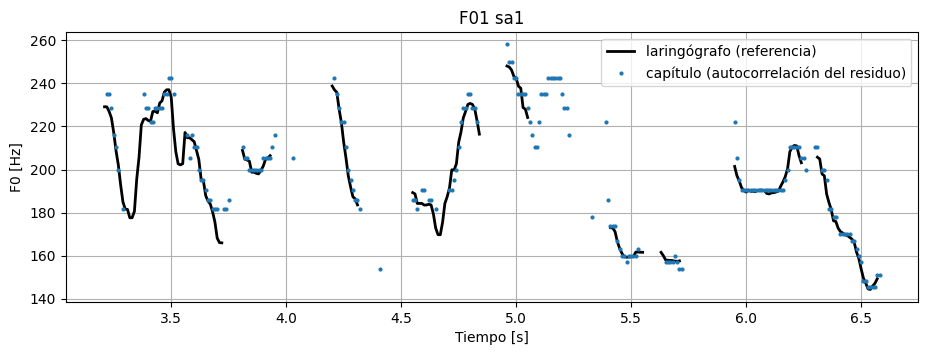

VDE = 8.4 %   GPE = 0.0 %   FPE = 1.9 %


In [14]:
def metricas(f0_est, f0_ref):
    n = min(len(f0_est), len(f0_ref))
    e, r = f0_est[:n], f0_ref[:n]
    vde = np.mean((e > 0) != (r > 0)) * 100
    ambas = (e > 0) & (r > 0)
    err_rel = (e[ambas] - r[ambas]) / r[ambas]
    grueso = np.abs(err_rel) > 0.2
    gpe = np.mean(grueso) * 100 if ambas.any() else np.nan
    fpe = np.std(err_rel[~grueso]) * 100 if (~grueso).any() else np.nan
    return vde, gpe, fpe

t_tr = np.arange(len(f0_cap)) * SALTO / FS
t_ref = np.arange(len(f0_ref)) * 0.01
plt.plot(t_ref, np.where(f0_ref > 0, f0_ref, np.nan), "k", lw=2, label="laringógrafo (referencia)")
plt.plot(t_tr, np.where(f0_cap > 0, f0_cap, np.nan), ".", ms=4, label="capítulo (autocorrelación del residuo)")
plt.xlabel("Tiempo [s]"); plt.ylabel("F0 [Hz]"); plt.legend(); plt.title("F01 sa1")
plt.savefig(FIG_DIR / "01_f0_vs_referencia.png", dpi=120, bbox_inches="tight"); plt.show()

vde, gpe, fpe = metricas(f0_cap, f0_ref)
print(f"VDE = {vde:.1f} %   GPE = {gpe:.1f} %   FPE = {fpe:.1f} %")

### 7.1 Las 8 señales de la prueba (2 mujeres, 2 hombres, frases sa1 y sa2)

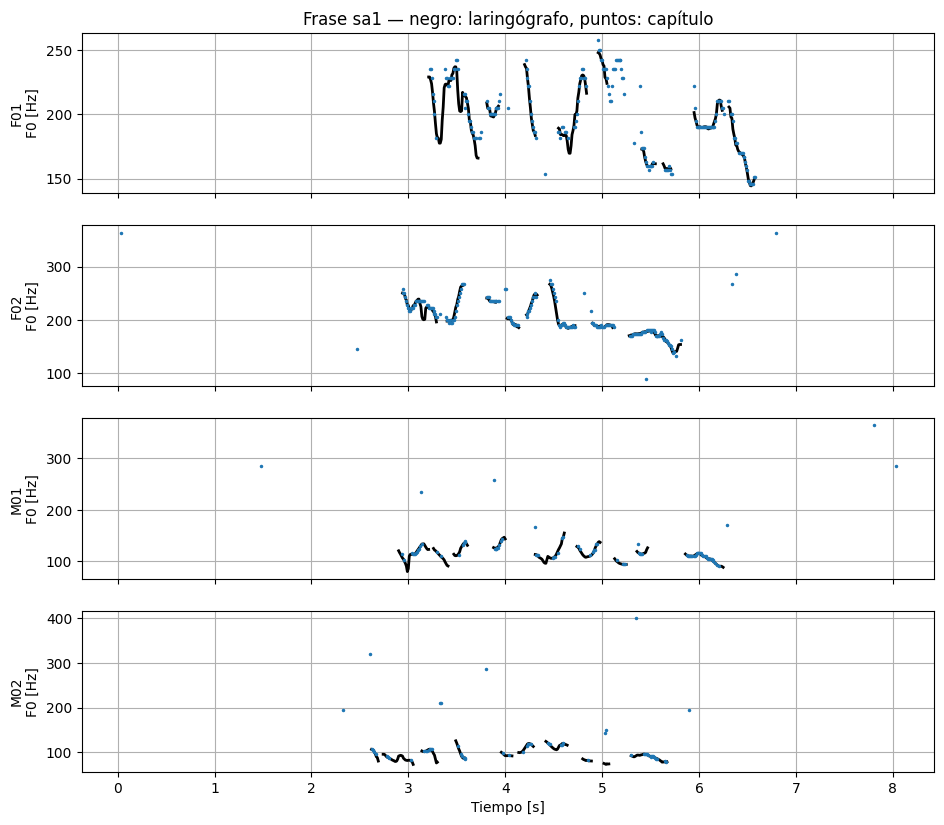

hablante sexo frase  VDE %  GPE %  FPE %  F0 ref media
F01      F    sa1      8.4    0.0    1.9        195 Hz
F01      F    sa2      5.1    0.0    1.7        190 Hz
F02      F    sa1      4.0    0.6    2.6        200 Hz
F02      F    sa2      3.1   12.0    1.3        189 Hz
M01      M    sa1     13.9    3.5    2.0        114 Hz
M01      M    sa2      8.3    3.4    1.3        113 Hz
M02      M    sa1     18.5    5.7    1.4         95 Hz
M02      M    sa2      9.2    0.0    2.5         99 Hz
Promedio mujeres: VDE 5.1 %  GPE 3.1 %  FPE 1.9 %
Promedio hombres: VDE 12.5 %  GPE 3.1 %  FPE 1.8 %


In [15]:
filas = []
fig, axes = plt.subplots(len(HABLANTES), 1, figsize=(11, 2.4 * len(HABLANTES)), sharex=True)
for ax, h in zip(axes, HABLANTES):
    for f in FRASES:
        _, x48_, ref_ = cargar(h, f)
        s_ = preprocesar(x48_)
        n_ = (len(s_) - L_TRAMA) // SALTO + 1
        f0_ = np.array([FS / T if (T := pitch(s_[i * SALTO:i * SALTO + L_TRAMA])) > 0 else 0.0 for i in range(n_)])
        filas.append((h, "F" if h.startswith("F") else "M", f, *metricas(f0_, ref_), ref_[ref_ > 0].mean()))
        if f == "sa1":
            ax.plot(np.arange(len(ref_)) * 0.01, np.where(ref_ > 0, ref_, np.nan), "k", lw=2)
            ax.plot(np.arange(n_) * 0.01, np.where(f0_ > 0, f0_, np.nan), ".", ms=3)
            ax.set_ylabel(f"{h}\nF0 [Hz]")
axes[-1].set_xlabel("Tiempo [s]"); axes[0].set_title("Frase sa1 — negro: laringógrafo, puntos: capítulo")
plt.savefig(FIG_DIR / "01_f0_cuatro_hablantes.png", dpi=120, bbox_inches="tight"); plt.show()

print(f"{'hablante':8} {'sexo':4} {'frase':5} {'VDE %':>6} {'GPE %':>6} {'FPE %':>6} {'F0 ref media':>13}")
for h, sx, f, vde, gpe, fpe, f0m in filas:
    print(f"{h:8} {sx:4} {f:5} {vde:6.1f} {gpe:6.1f} {fpe:6.1f} {f0m:10.0f} Hz")
for sx in "FM":
    v = np.array([r_[3:6] for r_ in filas if r_[1] == sx])
    print(f"Promedio {'mujeres' if sx == 'F' else 'hombres'}: VDE {v[:, 0].mean():.1f} %  GPE {v[:, 1].mean():.1f} %  FPE {v[:, 2].mean():.1f} %")

## 8. Observaciones para la reunión con el tutor

_Completar en grupo después de correr y escuchar._

- ¿Cómo suena la voz LPC10 con la F0 del capítulo frente a la del laringógrafo?
- ¿Dónde se equivoca más el estimador del capítulo: decisión sonoro/sordo o valor de F0? ¿Difiere entre mujeres y hombres?
- Umbral sonoro/sordo: el capítulo no lo da; ¿es razonable elegirlo con un subconjunto de la base?
- Próximo paso: agregar cepstrum y YIN como estimadores alternativos y meter cada uno en `lpc10(..., f0_externa=...)`.